# ⚡ **Household Energy Consumption Prediction**

**Supervised Learning | Time Series Regression | Linear Regression**

This project predicts the **next hour’s average household active power (kW)** using past measurements and calendar features.

## **Introduction**

Understanding household energy usage helps identify consumption patterns and plan electricity demand. Here we analyze minute-level power measurements recorded at one household in France between December 2006 and November 2010.

**Original source:** [UCI – Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption)  
**Kaggle source** [Electric Power Consumption Data Set](https://www.kaggle.com/datasets/uciml/electric-power-consumption-data-set)

The dataset contains more than 2 million minute-level observations. We convert the measurements to hourly averages to keep the analysis efficient.

## **Problem Definition**

**Question:** Can we predict the *next hour's* average active power consumption from the latest known consumption and time-related features?

- **Machine Learning task:** Supervised Learning – Regression (one-step-ahead time-series forecasting)
- **Target (y):** Next hour's average `Global_active_power` (kW)
- **Features (X):** Current hour's power, past hourly power, and next hour's calendar information
- **Evaluation:** MAE, RMSE, R²; compared with a simple persistence baseline

We use a **chronological** 80%/20% split instead of shuffling time-series observations

## **Data Dictionary**

| Column | Meaning | Unit |
|---|---|---|
| `Date`, `Time` | Timestamp of each measurement | — |
| `Global_active_power` | Whole-house active power | kW |
| `Global_reactive_power` | Whole-house reactive power | kvar |
| `Voltage` | Average voltage | V |
| `Global_intensity` | Average current | A |
| `Sub_metering_1` | Kitchen sub-meter | Wh |
| `Sub_metering_2` | Laundry room sub-meter | Wh |
| `Sub_metering_3` | Water heater and air conditioner sub-meter | Wh |

To keep this project focused, the forecasting model uses **past active power and calendar features**. Other measurements are described here but not included in the model

## **Import Libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## **Load Data**

Place `household_power_consumption.txt` in the same directory as the notebook. The raw file uses semicolons as delimiters; missing measurements are marked with `?`.

For speed, we only load the columns needed for forecasting.

In [2]:
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";", usecols=["Date", "Time", "Global_active_power"],
    na_values="?"
)
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S"
)
df.head()

,Date,Time,Global_active_power,Datetime
0,16/12/2006,17:24:00,4.216,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,2006-12-16 17:28:00


## **Data Overview & Cleaning**

In [3]:
print("Shape:", df.shape)
print("Missing power measurements:", df["Global_active_power"].isna().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())
df["Global_active_power"].describe().round(2)

Shape: (2075259, 4)
Missing power measurements: 25979
Duplicate timestamps: 0


count    2049280.00
mean           1.09
std            1.06
min            0.08
25%            0.31
50%            0.60
75%            1.53
max           11.12
Name: Global_active_power, dtype: float64

>**Why hourly resampling?**

The original dataset contains electricity measurements recorded every minute. We convert these measurements into hourly averages to reduce data size and make consumption patterns easier to analyze.

We keep the original time order. Hours without valid measurements are excluded from the modeling data to avoid treating missing values as zero consumption.

This allows us to predict the average electricity usage for the next hour

In [4]:
hourly = (df.set_index("Datetime")["Global_active_power"]
          .resample("h").mean().to_frame("Power_kW"))
print("Total hours:", len(hourly))
print("Hours without readings:", hourly["Power_kW"].isna().sum())
hourly.head()

Total hours: 34589
Hours without readings: 421


,Power_kW
Datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467


## **Exploratory Data Analysis**

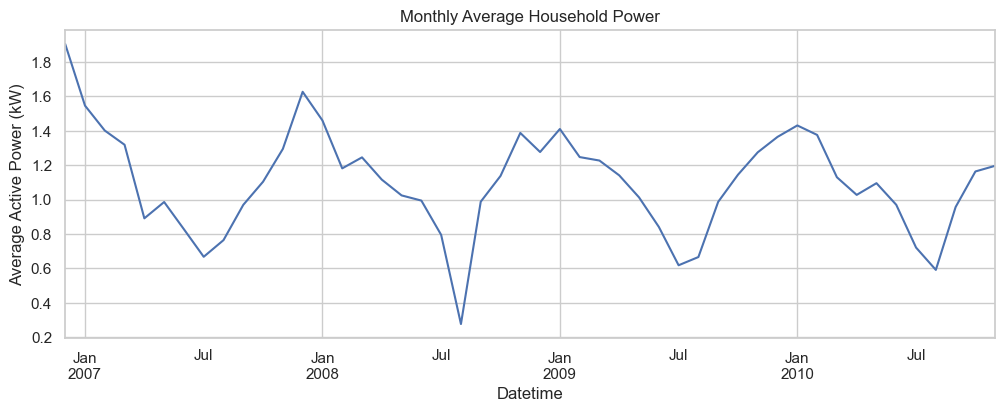

In [5]:
hourly["Power_kW"].resample("ME").mean().plot(figsize=(12, 4))
plt.title("Monthly Average Household Power")
plt.ylabel("Average Active Power (kW)")
plt.show()

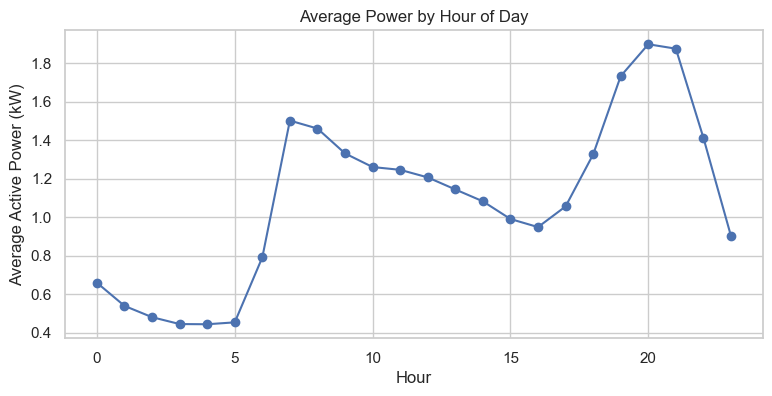

In [6]:
hourly.groupby(hourly.index.hour)["Power_kW"].mean().plot(marker="o", figsize=(9, 4))
plt.title("Average Power by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average Active Power (kW)")
plt.show()

These charts explore long-term and daily patterns. The next step turns these patterns into predictors for the **next** hour rather than the same hour

## **Feature Engineering**

>**Why do we use it?**

We create new features from previous electricity measurements to help the model recognize consumption patterns

- `Power_kW`: Electricity consumption in the current hour 
- `Power_lag_24h`: Consumption at the same hour one day earlier 
- `Power_lag_168h`: Consumption at the same hour one week earlier 
- `Hour`, `DayOfWeek`, `Month`: Calendar information for the next hour 
- `Target_next_hour`: The electricity consumption we want to predict 

These features help the model learn hourly, daily, and weekly consumption patterns to predict electricity usage for the next hour

In [7]:
data = hourly.copy()
data["Power_lag_24h"] = data["Power_kW"].shift(24)
data["Power_lag_168h"] = data["Power_kW"].shift(168)
data["Target_next_hour"] = data["Power_kW"].shift(-1)

# At the end of the current hour, predict the following hour.
next_hour = data.index + pd.Timedelta(hours=1)
data["Hour"] = next_hour.hour
data["DayOfWeek"] = next_hour.dayofweek
data["Month"] = next_hour.month

features = ["Power_kW", "Power_lag_24h", "Power_lag_168h", "Hour", "DayOfWeek", "Month"]
data = data.dropna(subset=features + ["Target_next_hour"])
print("Training-ready observations:", len(data))
data.head()

Training-ready observations: 33411


,Power_kW,Power_lag_24h,Power_lag_168h,Target_next_hour,Hour,DayOfWeek,Month
Datetime,,,,,,,
2006-12-23 17:00:00,5.452533,1.496800,4.222889,3.879400,18,5,12
2006-12-23 18:00:00,3.879400,2.686967,3.632200,4.117833,19,5,12
2006-12-23 19:00:00,4.117833,3.938167,3.400233,4.181400,20,5,12
2006-12-23 20:00:00,4.181400,3.536067,3.268567,3.288433,21,5,12
2006-12-23 21:00:00,3.288433,4.548667,3.056467,4.327933,22,5,12


**Leakage prevention:** All power predictors refer to the current or earlier hours. The target is the following hour. No future consumption measurements are used as features. Missing hours are not filled using future observations

## **Train / Test Split**

>**Why chronological splitting?**

We split the dataset into 80% training data and 20% testing data.

Because this is a time series problem, we keep the chronological order instead of using a random split.

The model learns from earlier observations and is evaluated on later observations. This better represents a real forecasting scenario and helps prevent data leakage

In [8]:
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]
x_train, y_train = train[features], train["Target_next_hour"]
x_test, y_test = test[features], test["Target_next_hour"]
print("Train:", len(train), "| Test:", len(test))
print("Test period:", test.index.min(), "to", test.index.max())

Train: 26728 | Test: 6683
Test period: 2010-01-29 09:00:00 to 2010-11-26 20:00:00


## **Linear Regression Model**

In [9]:
model = LinearRegression()
model.fit(x_train, y_train)
pred = model.predict(x_test)

# Baseline: assume the next hour will match the current hour.
baseline = x_test["Power_kW"].to_numpy()

## **Model Evaluation**

In [10]:
def evaluate(name, actual, prediction):
    return {
        "Model": name,
        "MAE (kW)": mean_absolute_error(actual, prediction),
        "RMSE (kW)": mean_squared_error(actual, prediction) ** 0.5,
        "R²": r2_score(actual, prediction),
    }

results = pd.DataFrame([
    evaluate("Previous-hour baseline", y_test, baseline),
    evaluate("Linear Regression", y_test, pred),
]).set_index("Model")
results.round(3)

,MAE (kW),RMSE (kW),R²
Model,,,
Previous-hour baseline,0.399,0.605,0.353
Linear Regression,0.396,0.549,0.467


>**Evaluation Metrics**

- **MAE:** Average absolute difference between actual and predicted values.
- **RMSE:** Measures prediction errors, giving more weight to larger errors.
- **R²:** Shows how well the model explains variation in the target variable.

Lower MAE and RMSE values indicate better predictions, while a higher R² generally indicates better model performance

## **Actual vs Predicted**

In [11]:
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(), "Predicted": pred
}, index=y_test.index + pd.Timedelta(hours=1))
comparison.head()

,Actual,Predicted
Datetime,,
2010-01-29 10:00:00,2.093667,1.691001
2010-01-29 11:00:00,2.120200,1.790579
2010-01-29 12:00:00,1.774600,1.813958
2010-01-29 13:00:00,1.585467,1.578009
2010-01-29 14:00:00,1.553867,1.399954


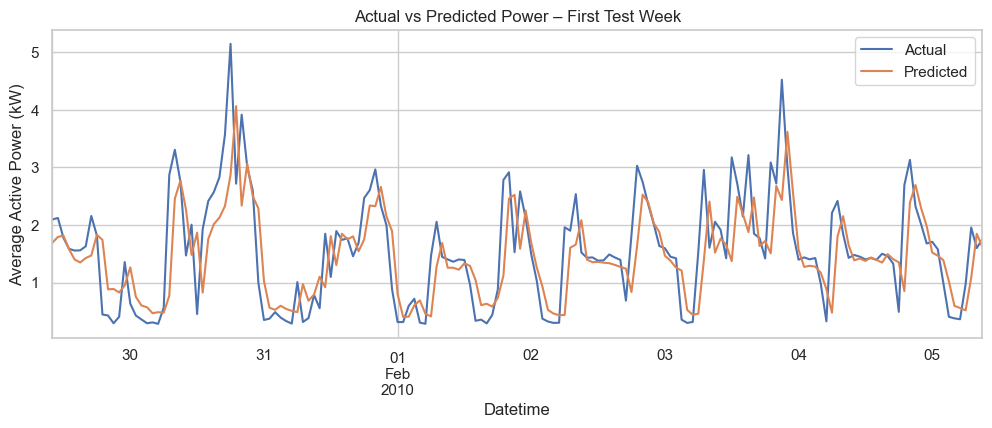

In [12]:
comparison.iloc[:168].plot(figsize=(12, 4))
plt.title("Actual vs Predicted Power – First Test Week")
plt.ylabel("Average Active Power (kW)")
plt.show()

## **Residual Analysis**

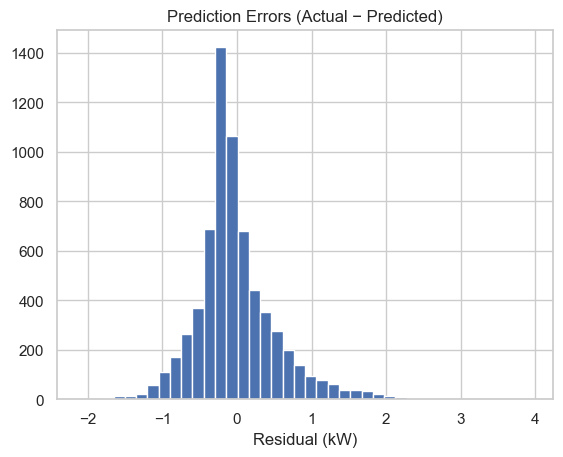

In [13]:
residuals = y_test.to_numpy() - pred
plt.hist(residuals, bins=40)
plt.title("Prediction Errors (Actual − Predicted)")
plt.xlabel("Residual (kW)")
plt.show()

>**Visualization Insights**

- **Actual vs Predicted:** The model captures general consumption patterns but struggles with sudden changes in electricity demand.
- **Residual Analysis:** Prediction errors are distributed around zero, with some larger errors indicating periods of less accurate predictions.

## **Conclusion**

This project used Linear Regression to predict the next hour's average household electrical power demand (kW).

We cleaned the original dataset, converted minute-level measurements into hourly averages, created time-based features, and trained the model using chronological data splitting.

**Final Results:**

- MAE: 0.396 kW
- RMSE: 0.549 kW
- R²: 0.467

The model performed better than the simple baseline, but its prediction accuracy remains moderate.

**Future Improvements:** More advanced models, additional features, and improved handling of consumption peaks could help improve forecasting performance.